In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
pd.set_option('display.max_columns', 15)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [2]:
def average(lst):
    if not lst:
        return 0
    return sum(lst) / len(lst)

In [3]:
movie = pd.read_csv('movies.csv')
rating = pd.read_csv('ratings.csv')

#Veri setlerinin birleştirilmesi
df = movie.merge(rating, how="left", on="movieId")

In [4]:
df

,movieId,title,genres,userId,rating,timestamp
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1.0,4.0,9.649827e+08
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,5.0,4.0,8.474350e+08
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,7.0,4.5,1.106636e+09
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,15.0,2.5,1.510578e+09
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,17.0,4.5,1.305696e+09
...,...,...,...,...,...,...
100849,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy,184.0,4.0,1.537109e+09
100850,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy,184.0,3.5,1.537110e+09
100851,193585,Flint (2017),Drama,184.0,3.5,1.537110e+09
100852,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation,184.0,3.5,1.537110e+09


In [5]:
ıdsayısı = df['userId'].nunique()
ıdsayısı

610

In [6]:
filmsayısı = df['title'].nunique()
filmsayısı

9737

In [7]:
df = df.drop(columns=['timestamp'])
df = df.drop(columns=['genres'])
df=df.dropna() # Null değerlerin kaldırılması

In [8]:
df.head()

,movieId,title,userId,rating
0,1,Toy Story (1995),1.0,4.0
1,1,Toy Story (1995),5.0,4.0
2,1,Toy Story (1995),7.0,4.5
3,1,Toy Story (1995),15.0,2.5
4,1,Toy Story (1995),17.0,4.5


In [9]:
df

,movieId,title,userId,rating
0,1,Toy Story (1995),1.0,4.0
1,1,Toy Story (1995),5.0,4.0
2,1,Toy Story (1995),7.0,4.5
3,1,Toy Story (1995),15.0,2.5
4,1,Toy Story (1995),17.0,4.5
...,...,...,...,...
100849,193581,Black Butler: Book of the Atlantic (2017),184.0,4.0
100850,193583,No Game No Life: Zero (2017),184.0,3.5
100851,193585,Flint (2017),184.0,3.5
100852,193587,Bungo Stray Dogs: Dead Apple (2018),184.0,3.5


In [10]:
movie_counts = df['title'].value_counts().reset_index() 
movie_counts.columns = ['title', 'count']


In [11]:
movie_counts

,title,count
0,Forrest Gump (1994),329
1,"Shawshank Redemption, The (1994)",317
2,Pulp Fiction (1994),307
3,"Silence of the Lambs, The (1991)",279
4,"Matrix, The (1999)",278
...,...,...
9714,Black Butler: Book of the Atlantic (2017),1
9715,No Game No Life: Zero (2017),1
9716,Flint (2017),1
9717,Bungo Stray Dogs: Dead Apple (2018),1


In [12]:
df.info()

<class 'pandas.DataFrame'>
Index: 100836 entries, 0 to 100853
Data columns (total 4 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   movieId  100836 non-null  int64  
 1   title    100836 non-null  str    
 2   userId   100836 non-null  float64
 3   rating   100836 non-null  float64
dtypes: float64(2), int64(1), str(1)
memory usage: 3.8 MB


In [13]:
common_movies  = movie_counts[movie_counts["count"] > 100]

In [14]:
common_movies 

,title,count
0,Forrest Gump (1994),329
1,"Shawshank Redemption, The (1994)",317
2,Pulp Fiction (1994),307
3,"Silence of the Lambs, The (1991)",279
4,"Matrix, The (1999)",278
...,...,...
129,Full Metal Jacket (1987),102
130,Harry Potter and the Chamber of Secrets (2002),102
131,Outbreak (1995),101
132,Cliffhanger (1993),101


In [15]:
common_movies = df[df['title'].isin(common_movies['title'])]


In [16]:
common_movies

,movieId,title,userId,rating
0,1,Toy Story (1995),1.0,4.0
1,1,Toy Story (1995),5.0,4.0
2,1,Toy Story (1995),7.0,4.5
3,1,Toy Story (1995),15.0,2.5
4,1,Toy Story (1995),17.0,4.5
...,...,...,...,...
91511,79132,Inception (2010),596.0,4.0
91512,79132,Inception (2010),598.0,5.0
91513,79132,Inception (2010),599.0,3.0
91514,79132,Inception (2010),601.0,5.0


In [17]:
ıdsayısı = common_movies['userId'].nunique()
ıdsayısı

597

In [18]:
filmsayısı = common_movies['title'].nunique()
filmsayısı

134

In [19]:

user_movie_df = common_movies.pivot_table(index=["userId"], columns=["title"], values="rating",fill_value=0)

user_movie_df

title,2001: A Space Odyssey (1968),Ace Ventura: Pet Detective (1994),Aladdin (1992),Alien (1979),Aliens (1986),"Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",American Beauty (1999),...,Twister (1996),Up (2009),"Usual Suspects, The (1995)",WALL·E (2008),Waterworld (1995),Willy Wonka & the Chocolate Factory (1971),X-Men (2000)
userId,,,,,,,,,,,,,,,
1.0,0.0,0.0,0.0,4.0,0.0,0.0,5.0,...,3.0,0.0,5.0,0.0,0.0,5.0,5.0
2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4.0,0.0,0.0,4.0,0.0,0.0,0.0,5.0,...,0.0,0.0,0.0,0.0,0.0,4.0,0.0
5.0,0.0,3.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,4.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606.0,5.0,0.0,0.0,4.0,3.5,4.5,4.5,...,0.0,0.0,4.5,4.0,0.0,0.0,0.0
607.0,0.0,0.0,0.0,3.0,0.0,0.0,3.0,...,5.0,0.0,0.0,0.0,3.0,0.0,3.0
608.0,3.0,3.5,3.0,4.0,4.5,0.0,5.0,...,3.0,0.0,4.5,0.0,3.0,3.5,4.0


In [20]:
user_movie_df.head()

title,2001: A Space Odyssey (1968),Ace Ventura: Pet Detective (1994),Aladdin (1992),Alien (1979),Aliens (1986),"Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",American Beauty (1999),...,Twister (1996),Up (2009),"Usual Suspects, The (1995)",WALL·E (2008),Waterworld (1995),Willy Wonka & the Chocolate Factory (1971),X-Men (2000)
userId,,,,,,,,,,,,,,,
1.0,0.0,0.0,0.0,4.0,0.0,0.0,5.0,...,3.0,0.0,5.0,0.0,0.0,5.0,5.0
2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4.0,0.0,0.0,4.0,0.0,0.0,0.0,5.0,...,0.0,0.0,0.0,0.0,0.0,4.0,0.0
5.0,0.0,3.0,4.0,0.0,0.0,0.0,0.0,...,0.0,0.0,4.0,0.0,0.0,0.0,0.0


movie_name = "Lion King, The (1994)"

movie_name = user_movie_df[movie_name]
print(type(movie_name))
print(movie_name)

user_movie_df.corrwith(movie_name).sort_values(ascending=False).head(3)

In [21]:
# Bu kod bloğu, film_sayisi parametresinde belirtilen sayıya göre, en iyi ikili, üçlü ya da dörtlü film gruplarını bulur

max_benzerlik = 0
best_movie = ""
close_list = []
film_sayisi = 10 
for x in user_movie_df.columns:
    movie_name = user_movie_df[x]
    close_movies= user_movie_df.corrwith(movie_name).sort_values(ascending=False).head(film_sayisi+1)
    movie_average = average(list(close_movies[1:film_sayisi+1]))
    if movie_average >  max_benzerlik:
        max_benzerlik = movie_average
        best_movie=x
        close_list = close_movies
      

In [22]:
max_benzerlik

0.5720631321019252

In [23]:
close_list # En yakın x film bunlar

title
Star Wars: Episode V - The Empire Strikes Back (1980)                             1.000000
Star Wars: Episode IV - A New Hope (1977)                                         0.736378
Star Wars: Episode VI - Return of the Jedi (1983)                                 0.709717
Indiana Jones and the Last Crusade (1989)                                         0.589973
Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)    0.586304
Terminator, The (1984)                                                            0.552509
Aliens (1986)                                                                     0.517670
Matrix, The (1999)                                                                0.516301
Indiana Jones and the Temple of Doom (1984)                                       0.506617
Back to the Future (1985)                                                         0.504465
Star Wars: Episode I - The Phantom Menace (1999)                                  0.

In [24]:
close_common_movies = common_movies[common_movies['title'].isin(close_list.index[1:])] 
# Yukarıda film listesinde ilki hariç diğer tüm filmleri alıp, common_movies tablomu bu filmlere göre filtreledim


In [25]:
close_common_movies # En benzer 10 filme kullanıcıların verdiği  puanlar

,movieId,title,userId,rating
6853,260,Star Wars: Episode IV - A New Hope (1977),1.0,5.0
6854,260,Star Wars: Episode IV - A New Hope (1977),4.0,5.0
6855,260,Star Wars: Episode IV - A New Hope (1977),7.0,5.0
6856,260,Star Wars: Episode IV - A New Hope (1977),15.0,5.0
6857,260,Star Wars: Episode IV - A New Hope (1977),16.0,3.0
...,...,...,...,...
45943,2628,Star Wars: Episode I - The Phantom Menace (1999),603.0,1.0
45944,2628,Star Wars: Episode I - The Phantom Menace (1999),606.0,3.5
45945,2628,Star Wars: Episode I - The Phantom Menace (1999),607.0,3.0
45946,2628,Star Wars: Episode I - The Phantom Menace (1999),608.0,4.0


In [26]:
close_common_movies_filtered = close_common_movies.groupby('userId').filter(lambda x: len(x) >= 10)
# En yakın 10 filmin, 10'unu da izleyip puanlayan kullanıcılar

In [27]:
close_common_movies_filtered

,movieId,title,userId,rating
6860,260,Star Wars: Episode IV - A New Hope (1977),19.0,4.0
6861,260,Star Wars: Episode IV - A New Hope (1977),21.0,4.5
6873,260,Star Wars: Episode IV - A New Hope (1977),57.0,5.0
6879,260,Star Wars: Episode IV - A New Hope (1977),68.0,5.0
6893,260,Star Wars: Episode IV - A New Hope (1977),91.0,4.5
...,...,...,...,...
45935,2628,Star Wars: Episode I - The Phantom Menace (1999),590.0,2.5
45941,2628,Star Wars: Episode I - The Phantom Menace (1999),599.0,3.0
45942,2628,Star Wars: Episode I - The Phantom Menace (1999),600.0,1.0
45943,2628,Star Wars: Episode I - The Phantom Menace (1999),603.0,1.0


In [28]:
# close_common_movies_filtered[close_common_movies_filtered["userId"]==483.0]

In [29]:
unique_user_count = close_common_movies_filtered['userId'].nunique()
unique_user_count # Toplam 33 kişi varmış, bunların bana sadece 10 tanesi lazım şuan

33

In [30]:
selected_users = np.random.choice(close_common_movies_filtered['userId'].unique(), 10, replace=False) # Rastgele 10 kişi seçtim
close_common_movies_filtered_10 = close_common_movies_filtered[close_common_movies_filtered['userId'].isin(selected_users)]

In [31]:
close_common_movies_filtered_10 # 10 film ve 10 kullanıcı 

,movieId,title,userId,rating
6879,260,Star Wars: Episode IV - A New Hope (1977),68.0,5.0
6893,260,Star Wars: Episode IV - A New Hope (1977),91.0,4.5
6927,260,Star Wars: Episode IV - A New Hope (1977),182.0,3.5
6936,260,Star Wars: Episode IV - A New Hope (1977),202.0,4.0
6957,260,Star Wars: Episode IV - A New Hope (1977),249.0,5.0
...,...,...,...,...
45873,2628,Star Wars: Episode I - The Phantom Menace (1999),298.0,3.0
45893,2628,Star Wars: Episode I - The Phantom Menace (1999),376.0,4.5
45900,2628,Star Wars: Episode I - The Phantom Menace (1999),414.0,4.0
45914,2628,Star Wars: Episode I - The Phantom Menace (1999),469.0,3.0


In [32]:
# filtered_10_avg = close_common_movies_filtered_10.groupby(['title',"userId"])['rating'].mean().reset_index()
# filtered_10_avg

In [33]:
filtered_10_avg = close_common_movies_filtered_10
filtered_10_avg['similarity'] = filtered_10_avg['title'].map(close_list)


In [34]:
filtered_10_avg

,movieId,title,userId,rating,similarity
6879,260,Star Wars: Episode IV - A New Hope (1977),68.0,5.0,0.736378
6893,260,Star Wars: Episode IV - A New Hope (1977),91.0,4.5,0.736378
6927,260,Star Wars: Episode IV - A New Hope (1977),182.0,3.5,0.736378
6936,260,Star Wars: Episode IV - A New Hope (1977),202.0,4.0,0.736378
6957,260,Star Wars: Episode IV - A New Hope (1977),249.0,5.0,0.736378
...,...,...,...,...,...
45873,2628,Star Wars: Episode I - The Phantom Menace (1999),298.0,3.0,0.500699
45893,2628,Star Wars: Episode I - The Phantom Menace (1999),376.0,4.5,0.500699
45900,2628,Star Wars: Episode I - The Phantom Menace (1999),414.0,4.0,0.500699
45914,2628,Star Wars: Episode I - The Phantom Menace (1999),469.0,3.0,0.500699


In [35]:
def weighted_average(group):
    ratings = group['rating']
    weights = group['similarity']
    return np.average(ratings, weights=weights)

In [36]:
filtered_10_weightedAvg = filtered_10_avg.groupby('userId').apply(weighted_average).reset_index(name='weighted_avg_rating')


In [37]:
filtered_10_weightedAvg

,userId,weighted_avg_rating
0,68.0,4.192086
1,91.0,4.307515
2,182.0,3.282073
3,202.0,3.980359
4,249.0,4.345865
5,298.0,3.937380
6,376.0,4.103793
7,414.0,4.720785
8,469.0,3.508539
9,599.0,4.158098


In [38]:
main_movie = common_movies[common_movies['title'].isin(close_list.index[:1])] 


In [39]:
main_movie = main_movie[main_movie["userId"].isin(selected_users)]

In [40]:
main_movie

,movieId,title,userId,rating
24669,1196,Star Wars: Episode V - The Empire Strikes Back...,68.0,5.0
24679,1196,Star Wars: Episode V - The Empire Strikes Back...,91.0,4.5
24706,1196,Star Wars: Episode V - The Empire Strikes Back...,182.0,3.0
24716,1196,Star Wars: Episode V - The Empire Strikes Back...,202.0,5.0
24736,1196,Star Wars: Episode V - The Empire Strikes Back...,249.0,5.0
24752,1196,Star Wars: Episode V - The Empire Strikes Back...,298.0,4.0
24782,1196,Star Wars: Episode V - The Empire Strikes Back...,376.0,4.0
24794,1196,Star Wars: Episode V - The Empire Strikes Back...,414.0,5.0
24809,1196,Star Wars: Episode V - The Empire Strikes Back...,469.0,5.0
24848,1196,Star Wars: Episode V - The Empire Strikes Back...,599.0,5.0


In [41]:
main_movie =pd.merge(main_movie,filtered_10_weightedAvg, on='userId')


In [42]:
main_movie

,movieId,title,userId,rating,weighted_avg_rating
0,1196,Star Wars: Episode V - The Empire Strikes Back...,68.0,5.0,4.192086
1,1196,Star Wars: Episode V - The Empire Strikes Back...,91.0,4.5,4.307515
2,1196,Star Wars: Episode V - The Empire Strikes Back...,182.0,3.0,3.282073
3,1196,Star Wars: Episode V - The Empire Strikes Back...,202.0,5.0,3.980359
4,1196,Star Wars: Episode V - The Empire Strikes Back...,249.0,5.0,4.345865
5,1196,Star Wars: Episode V - The Empire Strikes Back...,298.0,4.0,3.937380
6,1196,Star Wars: Episode V - The Empire Strikes Back...,376.0,4.0,4.103793
7,1196,Star Wars: Episode V - The Empire Strikes Back...,414.0,5.0,4.720785
8,1196,Star Wars: Episode V - The Empire Strikes Back...,469.0,5.0,3.508539
9,1196,Star Wars: Episode V - The Empire Strikes Back...,599.0,5.0,4.158098


In [43]:
mae = np.mean(np.abs(main_movie['rating'] - main_movie['weighted_avg_rating']))
mae

0.5735240400120365

In [44]:
# random_movie = user_movie_df.columns.to_series().sample(n=1).iloc[0]
# selected_movie_ratings = user_movie_df[random_movie]
# correlations = user_movie_df.corrwith(selected_movie_ratings)
# top_10_correlated_movies = correlations.sort_values(ascending=False).head(10)
# print(top_10_correlated_movies)

In [45]:
# Birbirine en benzer 10 filmi izlemiş 10 kullanıcı ile
#birbirine en çok benzeyen 10 kullanıcı farklı sonuç verebilir. Performans düşer

## Kullanıcı Tabanlı İşbirlikçi Filtreleme


In [46]:
user_similarity = cosine_similarity(user_movie_df)
user_similarity_df = pd.DataFrame(user_similarity, index=user_movie_df.index, columns=user_movie_df.index)

In [47]:
user_similarity_df

userId,1.0,2.0,3.0,4.0,5.0,6.0,7.0,...,604.0,605.0,606.0,607.0,608.0,609.0,610.0
userId,,,,,,,,,,,,,,,
1.0,1.000000,0.056296,0.149940,0.502701,0.317641,0.360316,0.364989,...,0.185122,0.304023,0.595505,0.565108,0.620801,0.246867,0.606943
2.0,0.056296,1.000000,0.000000,0.019890,0.046363,0.050349,0.035701,...,0.000000,0.000000,0.189484,0.049686,0.156093,0.073012,0.222647
3.0,0.149940,0.000000,1.000000,0.000000,0.274411,0.107280,0.000000,...,0.000000,0.000000,0.131511,0.176446,0.101169,0.000000,0.080407
4.0,0.502701,0.019890,0.000000,1.000000,0.198991,0.230690,0.308946,...,0.139434,0.264859,0.377129,0.360590,0.471025,0.073255,0.441904
5.0,0.317641,0.046363,0.274411,0.198991,1.000000,0.624101,0.211875,...,0.498556,0.387118,0.253337,0.364109,0.390052,0.466030,0.261621
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606.0,0.595505,0.189484,0.131511,0.377129,0.253337,0.286401,0.567226,...,0.213851,0.373437,1.000000,0.454345,0.850007,0.219934,0.819662
607.0,0.565108,0.049686,0.176446,0.360590,0.364109,0.451775,0.374480,...,0.313488,0.283333,0.454345,1.000000,0.595771,0.365994,0.568714
608.0,0.620801,0.156093,0.101169,0.471025,0.390052,0.466694,0.568533,...,0.357964,0.420190,0.850007,0.595771,1.000000,0.324610,0.815061


In [48]:
top_10_similar_users = {}
max_ort = 0
best_users = []
for userId in user_similarity_df.index:
    similar_users = user_similarity_df[userId].nlargest(11)
    similar_users = similar_users.drop(userId) 
    top_10_similar_users[userId] = similar_users
    ort = similar_users.mean()
    if ort > max_ort:
        max_ort= ort
        best_users = similar_users


In [49]:
best_users

userId
599.0    0.956996
480.0    0.942383
274.0    0.934821
474.0    0.931360
608.0    0.918094
68.0     0.911213
307.0    0.902457
590.0    0.897764
91.0     0.892742
483.0    0.890222
Name: 414.0, dtype: float64

In [50]:
best_users.name

414.0

In [51]:
result_df = pd.DataFrame([
    {'userId': userId, 'similar_user': similar_user, 'similarity_score': similarity_score}
    for userId, similar_users in top_10_similar_users.items()
    for similar_user, similarity_score in similar_users.items()
])

In [52]:
best_users_list = best_users.index.tolist()

print(best_users_list)


[599.0, 480.0, 274.0, 474.0, 608.0, 68.0, 307.0, 590.0, 91.0, 483.0]


In [53]:
best_users_list.append(best_users.name)

In [54]:
best_users_list

[599.0, 480.0, 274.0, 474.0, 608.0, 68.0, 307.0, 590.0, 91.0, 483.0, 414.0]

In [55]:
filtered_users = df[df['userId'].isin(best_users_list)]

In [56]:
filtered_users

,movieId,title,userId,rating
23,1,Toy Story (1995),68.0,2.5
32,1,Toy Story (1995),91.0,4.0
98,1,Toy Story (1995),274.0,4.0
113,1,Toy Story (1995),307.0,4.0
146,1,Toy Story (1995),414.0,4.0
...,...,...,...,...
100723,180985,The Greatest Showman (2017),414.0,3.5
100730,181315,Phantom Thread (2017),599.0,3.5
100754,183301,The Tale of the Bunny Picnic (1986),599.0,3.0
100780,184791,Fred Armisen: Standup for Drummers (2018),414.0,2.5


In [57]:
filtered_users_10movies = filtered_users.groupby('title').filter(lambda x: len(x) >= 11)


In [58]:
filtered_users_10movies

,movieId,title,userId,rating
23,1,Toy Story (1995),68.0,2.5
32,1,Toy Story (1995),91.0,4.0
98,1,Toy Story (1995),274.0,4.0
113,1,Toy Story (1995),307.0,4.0
146,1,Toy Story (1995),414.0,4.0
...,...,...,...,...
77665,8961,"Incredibles, The (2004)",480.0,3.5
77667,8961,"Incredibles, The (2004)",483.0,4.0
77683,8961,"Incredibles, The (2004)",590.0,4.0
77686,8961,"Incredibles, The (2004)",599.0,2.5


In [59]:
unique_10movies = filtered_users_10movies['title'].nunique()
unique_10movies 

80

In [60]:
selected_movies = np.random.choice(filtered_users_10movies['title'].unique(), 10, replace=False) 
selected_movies

array(['Shrek (2001)', 'Usual Suspects, The (1995)',
       'Indiana Jones and the Last Crusade (1989)',
       'Star Wars: Episode V - The Empire Strikes Back (1980)',
       'Big (1988)', 'Home Alone (1990)',
       'Independence Day (a.k.a. ID4) (1996)', 'Armageddon (1998)',
       'Shaun of the Dead (2004)', 'Jurassic Park (1993)'], dtype=object)

In [61]:
close_selected_movies = filtered_users_10movies[filtered_users_10movies['title'].isin(selected_movies)]

In [62]:
close_selected_movies

,movieId,title,userId,rating
2408,50,"Usual Suspects, The (1995)",68.0,3.0
2414,50,"Usual Suspects, The (1995)",91.0,4.5
2466,50,"Usual Suspects, The (1995)",274.0,4.0
2481,50,"Usual Suspects, The (1995)",307.0,4.5
2524,50,"Usual Suspects, The (1995)",414.0,5.0
...,...,...,...,...
77250,8874,Shaun of the Dead (2004),480.0,4.0
77251,8874,Shaun of the Dead (2004),483.0,4.5
77267,8874,Shaun of the Dead (2004),590.0,3.0
77269,8874,Shaun of the Dead (2004),599.0,3.0


In [63]:
best_users_df = best_users.reset_index()
best_users_df.columns = ['userId', 'similarity']

In [64]:
close_selected_movies_weighted = pd.merge(close_selected_movies, best_users_df, on='userId')


In [65]:
del close_selected_movies_weighted["movieId"]
close_selected_movies_weighted

,title,userId,rating,similarity
0,"Usual Suspects, The (1995)",68.0,3.0,0.911213
1,"Usual Suspects, The (1995)",91.0,4.5,0.892742
2,"Usual Suspects, The (1995)",274.0,4.0,0.934821
3,"Usual Suspects, The (1995)",307.0,4.5,0.902457
4,"Usual Suspects, The (1995)",474.0,4.0,0.931360
...,...,...,...,...
95,Shaun of the Dead (2004),480.0,4.0,0.942383
96,Shaun of the Dead (2004),483.0,4.5,0.890222
97,Shaun of the Dead (2004),590.0,3.0,0.897764
98,Shaun of the Dead (2004),599.0,3.0,0.956996


In [66]:
movies_10_weightedAvg = close_selected_movies_weighted.groupby('title').apply(weighted_average).reset_index(name='weighted_avg_rating')


In [67]:
movies_10_weightedAvg

,title,weighted_avg_rating
0,Armageddon (1998),2.802021
1,Big (1988),3.552671
2,Home Alone (1990),2.360910
3,Independence Day (a.k.a. ID4) (1996),3.351944
4,Indiana Jones and the Last Crusade (1989),4.198863
5,Jurassic Park (1993),3.952288
6,Shaun of the Dead (2004),4.142039
7,Shrek (2001),3.891143
8,Star Wars: Episode V - The Empire Strikes Back...,4.555254
9,"Usual Suspects, The (1995)",4.042464


In [68]:
main_user= best_users.name

main_user = common_movies[common_movies['userId']==best_users.name]

In [69]:

main_user = close_selected_movies[close_selected_movies['userId']==best_users.name]



In [70]:
main_user

,movieId,title,userId,rating
2524,50,"Usual Suspects, The (1995)",414.0,5.0
13242,480,Jurassic Park (1993),414.0,4.0
15312,586,Home Alone (1990),414.0,3.0
18966,780,Independence Day (a.k.a. ID4) (1996),414.0,4.0
24794,1196,Star Wars: Episode V - The Empire Strikes Back...,414.0,5.0
29419,1291,Indiana Jones and the Last Crusade (1989),414.0,4.0
36533,1917,Armageddon (1998),414.0,4.0
48268,2797,Big (1988),414.0,4.0
61446,4306,Shrek (2001),414.0,4.0
77241,8874,Shaun of the Dead (2004),414.0,4.0


In [71]:
main_user = main_user[main_user["title"].isin(selected_movies)]

In [72]:
close_selected_movies

,movieId,title,userId,rating
2408,50,"Usual Suspects, The (1995)",68.0,3.0
2414,50,"Usual Suspects, The (1995)",91.0,4.5
2466,50,"Usual Suspects, The (1995)",274.0,4.0
2481,50,"Usual Suspects, The (1995)",307.0,4.5
2524,50,"Usual Suspects, The (1995)",414.0,5.0
...,...,...,...,...
77250,8874,Shaun of the Dead (2004),480.0,4.0
77251,8874,Shaun of the Dead (2004),483.0,4.5
77267,8874,Shaun of the Dead (2004),590.0,3.0
77269,8874,Shaun of the Dead (2004),599.0,3.0


main_user = main_user[main_user["title"].isin(close_selected_movies)]

In [73]:
main_user

,movieId,title,userId,rating
2524,50,"Usual Suspects, The (1995)",414.0,5.0
13242,480,Jurassic Park (1993),414.0,4.0
15312,586,Home Alone (1990),414.0,3.0
18966,780,Independence Day (a.k.a. ID4) (1996),414.0,4.0
24794,1196,Star Wars: Episode V - The Empire Strikes Back...,414.0,5.0
29419,1291,Indiana Jones and the Last Crusade (1989),414.0,4.0
36533,1917,Armageddon (1998),414.0,4.0
48268,2797,Big (1988),414.0,4.0
61446,4306,Shrek (2001),414.0,4.0
77241,8874,Shaun of the Dead (2004),414.0,4.0


In [74]:
main_user_res =pd.merge(main_user,movies_10_weightedAvg, on='title')


In [75]:
main_user_res

,movieId,title,userId,rating,weighted_avg_rating
0,50,"Usual Suspects, The (1995)",414.0,5.0,4.042464
1,480,Jurassic Park (1993),414.0,4.0,3.952288
2,586,Home Alone (1990),414.0,3.0,2.360910
3,780,Independence Day (a.k.a. ID4) (1996),414.0,4.0,3.351944
4,1196,Star Wars: Episode V - The Empire Strikes Back...,414.0,5.0,4.555254
5,1291,Indiana Jones and the Last Crusade (1989),414.0,4.0,4.198863
6,1917,Armageddon (1998),414.0,4.0,2.802021
7,2797,Big (1988),414.0,4.0,3.552671
8,4306,Shrek (2001),414.0,4.0,3.891143
9,8874,Shaun of the Dead (2004),414.0,4.0,4.142039


In [76]:
mae = np.mean(np.abs(main_user_res['rating'] - main_user_res['weighted_avg_rating']))
mae

0.4832208331892428

In [77]:
df_comparison= pd.merge(df, result_df, on='userId', how='inner')



user_column = df_comparison['userId']
user_column

In [78]:
num_unique_ids = df_comparison['userId'].nunique()
num_unique_ids

597

random_user_id = df_comparison['userId'].sample(1).iloc[0]
random_user = df_comparison[df_comparison['userId'] == random_user_id]
random_user

df_comparison['similar_user_rating'] = df_comparison.apply(lambda row: df_comparison.loc[df_comparison['userId'] == row['similar_user'], 'rating'].values[0], axis=1)
df_comparison

df_comparison['rating_difference'] =df_comparison['rating']- df_comparison['similar_user_rating'] 

df_comparison['weighted_similar_rating'] = df_comparison['rating_difference'] * df_comparison['similarity_score']
df_comparison

df_comparison_mea = df_comparison.groupby('title')['weighted_similar_rating'].mean().reset_index()


df_comparison_mea.sort_values('weighted_similar_rating',ascending=False)


rating_sum = film_filtered.groupby('userId')['rating'].mean().reset_index()


random_movie_id = random_user['movieId'].sample(1).iloc[0]
random_movie_id

In [79]:
user_movie_titles = df.groupby('userId')['title'].apply(list).reset_index()




user_610_titles = user_movie_titles[user_movie_titles['userId'] == 610]['title'].values[0]

user_610_titles

similar_users = df[(df['movieId'] == random_movie_id) & (df['userId'] == random_user_id)]
similar_users 

similar_users = top_10_similar_users[random_user_id]
weighted_ratings = []
similarity_scores = []

for similar_user_id, similarity_score in similar_users.items():
    similar_user_rating = df[(df['userId'] == similar_user_id) & (df['movieId'] == random_movie_id)]
    if not similar_user_rating.empty:
        similar_user_rating = similar_user_rating.iloc[0]['rating']
        weighted_ratings.append(similar_user_rating * similarity_score)
        similarity_scores.append(similarity_score)


total_weighted_rating = sum(weighted_ratings)
total_similarity_score = sum(similarity_scores)
weighted_average_rating = total_weighted_rating / total_similarity_score if total_similarity_score != 0 else 0

weighted_average_rating

In [80]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

In [81]:
df=common_movies

In [82]:

x = df[['userId', 'movieId']].values
y = df['rating'].values

In [83]:

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=15)

In [84]:

print("X Eğitim özelliklerinin boyutu:", x_train.shape)
print("X Test özelliklerinin boyutu:", x_test.shape)
print("Y Eğitim etiketlerinin boyutu:", y_train.shape)
print("Y Test etiketlerinin boyutu:", y_test.shape)

X Eğitim özelliklerinin boyutu: (15830, 2)
X Test özelliklerinin boyutu: (3958, 2)
Y Eğitim etiketlerinin boyutu: (15830,)
Y Test etiketlerinin boyutu: (3958,)


In [85]:

scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
x_train.shape

(15830, 2)

In [86]:
model = Sequential()
model.add(Dense(16, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(16, activation="relu"))
model.add(Dense(16, activation="relu"))

model.add(Dense(1))

model.compile(optimizer="adam",loss="mse")


In [87]:
model.fit(x=x_train, y = y_train,validation_data=(x_test,y_test),batch_size=16,epochs=20)

Epoch 1/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 4.6426 - val_loss: 0.9182
Epoch 2/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.9287 - val_loss: 0.9060
Epoch 3/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.9106 - val_loss: 0.9055
Epoch 4/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.9076 - val_loss: 0.9162
Epoch 5/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.9203 - val_loss: 0.9193
Epoch 6/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.8820 - val_loss: 0.9024
Epoch 7/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.9162 - val_loss: 0.9041
Epoch 8/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.8807 - val_loss: 0.9047
Epoch 9/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.9007 - val_loss: 0.9019
Epoch 10/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.9014 - val_loss: 0.9056
Epoch 11/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.8959 - val_loss: 0.9029
Epoch 12/20
990/990 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step

In [88]:
model.history.history

{'loss': [2.0845675468444824,
  0.9139378070831299,
  0.9097917079925537,
  0.9090045690536499,
  0.9093058705329895,
  0.9081452488899231,
  0.9067944884300232,
  0.9076570868492126,
  0.9082712531089783,
  0.9070920944213867,
  0.9065567255020142,
  0.9080076217651367,
  0.907208263874054,
  0.9054743051528931,
  0.9040660262107849,
  0.9045534133911133,
  0.905758798122406,
  0.9072791934013367,
  0.9062964916229248,
  0.9051288962364197],
 'val_loss': [0.9181761145591736,
  0.9059728980064392,
  0.9054926633834839,
  0.916230320930481,
  0.9192689061164856,
  0.9023731350898743,
  0.9041413068771362,
  0.9047256708145142,
  0.9018765687942505,
  0.905610203742981,
  0.9029279351234436,
  0.916390061378479,
  0.9019436836242676,
  0.9081307053565979,
  0.9027764201164246,
  0.901492178440094,
  0.9031655788421631,
  0.9025214910507202,
  0.9026885032653809,
  0.9020322561264038]}

In [89]:
kayipVerisi = pd.DataFrame(model.history.history)
kayipVerisi.head()

,loss,val_loss
0,2.084568,0.918176
1,0.913938,0.905973
2,0.909792,0.905493
3,0.909005,0.916230
4,0.909306,0.919269


<Axes: >

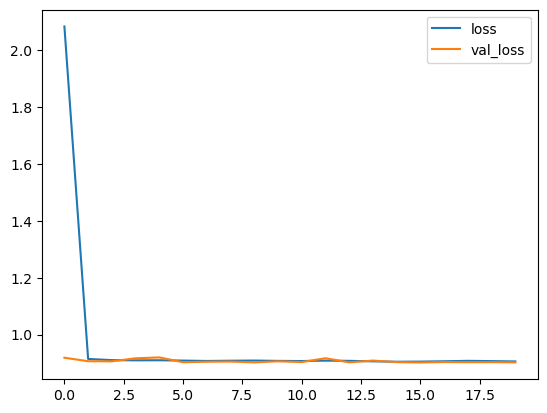

In [90]:
kayipVerisi.plot()

In [91]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [92]:
tahminDizisi = model.predict(x_test)

124/124 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [93]:
tahminDizisi

array([[3.859784 ],
       [3.9097922],
       [3.8513079],
       ...,
       [3.9057243],
       [3.906476 ],
       [3.8574333]], dtype=float32)

In [94]:
mean_absolute_error(y_test,tahminDizisi)

0.7285784691376419

In [95]:
df.describe()

,movieId,userId,rating
count,19788.000000,19788.000000,19788.000000
mean,3827.812967,309.300889,3.859536
std,11259.269863,179.151798,0.951663
min,1.000000,1.000000,0.500000
25%,364.000000,156.000000,3.000000
50%,1089.000000,307.500000,4.000000
75%,2716.000000,462.000000,4.500000
max,79132.000000,610.000000,5.000000



user_id_to_remove = 55
movie_id_to_remove = 48516
# Belirtilen userID ve movieID'ye sahip satırı seçin ve veri setinden çıkar
selected_sample = df[(df['userId'] == user_id_to_remove) & (df['movieId'] == movie_id_to_remove)]
df_without_sample = df[(df['userId'] != user_id_to_remove) | (df['movieId'] != movie_id_to_remove)].reset_index(drop=True)
# Seçilen örnek ile tahmin yapma
test_sample = selected_sample[['userId', 'movieId']].values  # userID ve movieID
true_rating = selected_sample['rating'].values[0]   # rating

# Modelle tahmin yapma
test_sample = np.expand_dims(test_sample[0], axis=0) 
predicted_rating = model.predict(test_sample)
predicted_rating = np.clip(predicted_rating, 0, 5)

print(f"Gerçek rating: {true_rating}")
print(f"Tahmin edilen rating: {predicted_rating[0][0]}")


In [96]:
# MAE hesaplamak için listeler
true_ratings = []
predicted_ratings = []

# Veri setindeki kullanıcılar ve filmler
unique_users = main_movie['userId'].unique()
unique_movies = main_movie['movieId'].unique()

for userId in unique_users:
    for movieId in unique_movies:
        # Belirtilen userID ve movieID'ye sahip satırı seç
        selected_sample = main_movie[(main_movie['userId'] == userId) & (main_movie['movieId'] == movieId)]
        if not selected_sample.empty:
            # Gerçek rating'i al
            true_rating = selected_sample['rating'].values[0]
            
            # Tahmin yapmak için model kullanma
            test_sample = np.array([[userId, movieId]])
            predicted_rating = model.predict(test_sample)
            predicted_rating = np.clip(predicted_rating, 0, 5)
            
            # Sonuçları sakla
            true_ratings.append(true_rating)
            predicted_ratings.append(predicted_rating[0])
            
            print(f"Kullanıcı ID: {userId}, Film ID: {movieId}")
            print(f"Gerçek rating: {true_rating}")
            print(f"Tahmin edilen rating: {predicted_rating[0]}")

# MAE hesaplama
if true_ratings and predicted_ratings:
    mae = np.mean(np.abs(np.array(true_ratings) - np.array(predicted_ratings)))
    print(f"Mean Absolute Error (MAE): {mae}")
else:
    print("MAE hesaplama için yeterli veri yok.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Kullanıcı ID: 68.0, Film ID: 1196
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Kullanıcı ID: 91.0, Film ID: 1196
Gerçek rating: 4.5
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Kullanıcı ID: 182.0, Film ID: 1196
Gerçek rating: 3.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Kullanıcı ID: 202.0, Film ID: 1196
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Kullanıcı ID: 249.0, Film ID: 1196
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Kullanıcı ID: 298.0, Film ID: 1196
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Kullanıcı ID: 376.0, Film ID: 1196
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Kullanıcı ID: 414.0, Film ID: 1196
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Kullanıcı ID

In [97]:
main_user_res

,movieId,title,userId,rating,weighted_avg_rating
0,50,"Usual Suspects, The (1995)",414.0,5.0,4.042464
1,480,Jurassic Park (1993),414.0,4.0,3.952288
2,586,Home Alone (1990),414.0,3.0,2.360910
3,780,Independence Day (a.k.a. ID4) (1996),414.0,4.0,3.351944
4,1196,Star Wars: Episode V - The Empire Strikes Back...,414.0,5.0,4.555254
5,1291,Indiana Jones and the Last Crusade (1989),414.0,4.0,4.198863
6,1917,Armageddon (1998),414.0,4.0,2.802021
7,2797,Big (1988),414.0,4.0,3.552671
8,4306,Shrek (2001),414.0,4.0,3.891143
9,8874,Shaun of the Dead (2004),414.0,4.0,4.142039


In [98]:
# MAE hesaplamak için listeler
true_ratings = []
predicted_ratings = []

# Veri setindeki kullanıcılar ve filmler
unique_users = main_user_res['userId'].unique()
unique_movies = main_user_res['movieId'].unique()

for userId in unique_users:
    for movieId in unique_movies:
        # Belirtilen userID ve movieID'ye sahip satırı seçin
        selected_sample = main_user_res[(main_user_res['userId'] == userId) & (main_user_res['movieId'] == movieId)]
        if not selected_sample.empty:
            # Gerçek rating'i al
            true_rating = selected_sample['rating'].values[0]
            
            # Tahmin yapmak için model kullanma
            test_sample = np.array([[userId, movieId]])
            predicted_rating = model.predict(test_sample)
            predicted_rating = np.clip(predicted_rating, 0, 5)
            
            # Sonuçları sakla
            true_ratings.append(true_rating)
            predicted_ratings.append(predicted_rating[0])
            
            print(f"Kullanıcı ID: {userId}, Film ID: {movieId}")
            print(f"Gerçek rating: {true_rating}")
            print(f"Tahmin edilen rating: {predicted_rating[0]}")

# MAE hesaplama
if true_ratings and predicted_ratings:
    mae = np.mean(np.abs(np.array(true_ratings) - np.array(predicted_ratings)))
    print(f"Mean Absolute Error (MAE): {mae}")
else:
    print("MAE hesaplama için yeterli veri yok.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Kullanıcı ID: 414.0, Film ID: 50
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
Kullanıcı ID: 414.0, Film ID: 480
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Kullanıcı ID: 414.0, Film ID: 586
Gerçek rating: 3.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Kullanıcı ID: 414.0, Film ID: 780
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Kullanıcı ID: 414.0, Film ID: 1196
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Kullanıcı ID: 414.0, Film ID: 1291
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Kullanıcı ID: 414.0, Film ID: 1917
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Kullanıcı ID: 414.0, Film ID: 2797
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Kullanıcı ID: 4

In [99]:
close_selected_movies

,movieId,title,userId,rating
2408,50,"Usual Suspects, The (1995)",68.0,3.0
2414,50,"Usual Suspects, The (1995)",91.0,4.5
2466,50,"Usual Suspects, The (1995)",274.0,4.0
2481,50,"Usual Suspects, The (1995)",307.0,4.5
2524,50,"Usual Suspects, The (1995)",414.0,5.0
...,...,...,...,...
77250,8874,Shaun of the Dead (2004),480.0,4.0
77251,8874,Shaun of the Dead (2004),483.0,4.5
77267,8874,Shaun of the Dead (2004),590.0,3.0
77269,8874,Shaun of the Dead (2004),599.0,3.0


# MAE hesaplamak için listeler
true_ratings = []
predicted_ratings = []

# Veri setindeki kullanıcılar ve filmler
unique_users = close_selected_movies['userId'].unique()
unique_movies = close_selected_movies['movieId'].unique()

for userId in unique_users:
    for movieId in unique_movies:
        # Belirtilen userID ve movieID'ye sahip satırı seçin
        selected_sample = close_selected_movies[(close_selected_movies['userId'] == userId) & (close_selected_movies['movieId'] == movieId)]
        if not selected_sample.empty:
            # Gerçek rating'i al
            true_rating = selected_sample['rating'].values[0]
            
            # Tahmin yapmak için model kullanma
            test_sample = np.array([[userId, movieId]])
            predicted_rating = model.predict(test_sample)
            predicted_rating = np.clip(predicted_rating, 0, 5)
            
            # Sonuçları sakla
            true_ratings.append(true_rating)
            predicted_ratings.append(predicted_rating[0])
            
            print(f"Kullanıcı ID: {userId}, Film ID: {movieId}")
            print(f"Gerçek rating: {true_rating}")
            print(f"Tahmin edilen rating: {predicted_rating[0]}")

# MAE hesaplama
if true_ratings and predicted_ratings:
    mae = np.mean(np.abs(np.array(true_ratings) - np.array(predicted_ratings)))
    print(f"Mean Absolute Error (MAE): {mae}")
else:
    print("MAE hesaplama için yeterli veri yok.")

In [100]:
# MAE hesaplamak için listeler
true_ratings = []
predicted_ratings = []

# Veri setindeki kullanıcılar ve filmler
unique_users = close_selected_movies['userId'].unique()
unique_movies = close_selected_movies['movieId'].unique()

for userId in unique_users:
    for movieId in unique_movies:
        # Belirtilen userID ve movieID'ye sahip satırı seçin
        selected_sample = close_selected_movies[(close_selected_movies['userId'] == userId) & (close_selected_movies['movieId'] == movieId)]
        if not selected_sample.empty:
            # Gerçek rating'i al
            true_rating = selected_sample['rating'].values[0]
            
            # Tahmin yapmak için model kullanma
            test_sample = np.array([[userId, movieId]])
            predicted_rating = model.predict(test_sample)
            predicted_rating = np.clip(predicted_rating, 0, 5)
            
            # Sonuçları sakla
            true_ratings.append(true_rating)
            predicted_ratings.append(predicted_rating[0])
            
            print(f"Kullanıcı ID: {userId}, Film ID: {movieId}")
            print(f"Gerçek rating: {true_rating}")
            print(f"Tahmin edilen rating: {predicted_rating[0]}")

# MAE hesaplama
if true_ratings and predicted_ratings:
    mae = np.mean(np.abs(np.array(true_ratings) - np.array(predicted_ratings)))
    print(f"Mean Absolute Error (MAE): {mae}")
else:
    print("MAE hesaplama için yeterli veri yok.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Kullanıcı ID: 68.0, Film ID: 50
Gerçek rating: 3.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Kullanıcı ID: 68.0, Film ID: 480
Gerçek rating: 3.5
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Kullanıcı ID: 68.0, Film ID: 586
Gerçek rating: 1.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Kullanıcı ID: 68.0, Film ID: 780
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Kullanıcı ID: 68.0, Film ID: 1196
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Kullanıcı ID: 68.0, Film ID: 1291
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Kullanıcı ID: 68.0, Film ID: 1917
Gerçek rating: 3.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Kullanıcı ID: 68.0, Film ID: 2797
Gerçek rating: 3.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Kullanıcı ID: 68.0, Fil

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Kullanıcı ID: 474.0, Film ID: 1196
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Kullanıcı ID: 474.0, Film ID: 1291
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Kullanıcı ID: 474.0, Film ID: 1917
Gerçek rating: 1.5
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Kullanıcı ID: 474.0, Film ID: 2797
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Kullanıcı ID: 474.0, Film ID: 4306
Gerçek rating: 4.5
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Kullanıcı ID: 474.0, Film ID: 8874
Gerçek rating: 4.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Kullanıcı ID: 480.0, Film ID: 50
Gerçek rating: 3.5
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Kullanıcı ID: 480.0, Film ID: 480
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Kullanıcı ID:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Kullanıcı ID: 608.0, Film ID: 4306
Gerçek rating: 4.5
Tahmin edilen rating: [5.]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Kullanıcı ID: 608.0, Film ID: 8874
Gerçek rating: 5.0
Tahmin edilen rating: [5.]
Mean Absolute Error (MAE): 1.2772727272727273
